# 05 · Read a profile of agreement

Use a fixed image-gradient representation. Magnitude-weighted circular moments m₁, m₂ and m₄ encode angular orders. On the circle, the Q-tensor contains exactly the two real components of m₂. We keep the full complex moments, so the profile compares orientation as well as strength.

## Setup
All examples use synthetic configurations. See THEORY.md for definitions, assumptions and proofs.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'observables').is_dir())
sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from observables.core import *
from observables.patterns import *
from observables.images import *
OUT=ROOT/'results'
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize':(7.5,3.5),'figure.dpi':110,
                    'figure.constrained_layout.use':True,'axes.spines.top':False,'axes.spines.right':False})
def show(name):
    plt.savefig(OUT/(name+'.png'),dpi=150)
    plt.show()
def unit_circle(angles):
    return np.column_stack([np.cos(angles),np.sin(angles)])
SEED=41

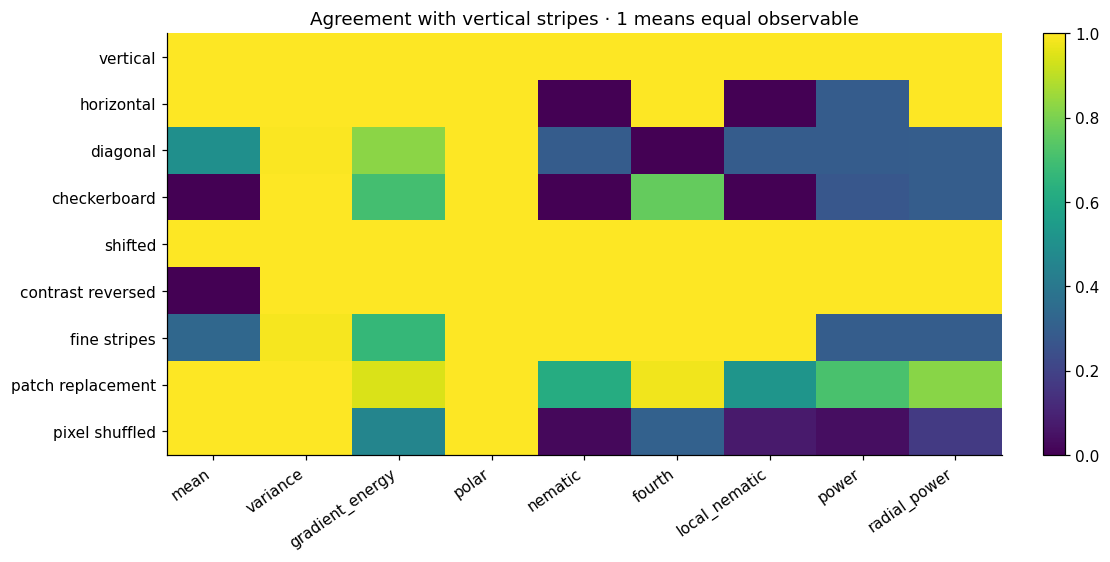

,mean,variance,gradient_energy,polar,nematic,fourth,local_nematic,power,radial_power
horizontal,1.000,1.000,1.000,1.0,0.000,1.000,0.000,0.293,1.000
shifted,1.000,1.000,1.000,1.0,1.000,1.000,1.000,1.000,1.000
contrast reversed,0.000,1.000,1.000,1.0,1.000,1.000,1.000,1.000,1.000
fine stripes,0.333,0.988,0.667,1.0,1.000,1.000,1.000,0.294,0.294
pixel shuffled,1.000,1.000,0.456,1.0,0.023,0.311,0.071,0.037,0.169


In [3]:
patterns=motif_gallery();reference=patterns['vertical']
scores=pd.DataFrame({name:profile(reference,im) for name,im in patterns.items()}).T
scores.to_csv(OUT/'image_profiles.csv')
fig,ax=plt.subplots(figsize=(10,5))
im=ax.imshow(scores,vmin=0,vmax=1,cmap='viridis',aspect='auto')
ax.set_xticks(range(len(scores.columns)),scores.columns,rotation=35,ha='right')
ax.set_yticks(range(len(scores)),scores.index)
ax.set_title('Agreement with vertical stripes · 1 means equal observable')
fig.colorbar(im,ax=ax);show('05_profile_matrix')
display(scores.loc[['horizontal','shifted','contrast reversed','fine stripes','pixel shuffled']].round(3))

## Which component retains each distinction?
- An intensity histogram agrees for all binary patterns with equal occupancy.
- Global m₂ distinguishes horizontal and vertical normals while treating their sign reversals equally.
- m₄ identifies fourfold angular order, but can identify perpendicular stripe axes with each other.
- Grid-local m₂ retains coarse locations of orientation. It depends on grid alignment.
- Full power retains periodic spacing and orientation, while removing translation phase.
- Radial power pools frequency directions into shells. This introduces an additional orientation ambiguity.

The magnitude-weighted global polar moment is identically zero for this periodic gradient representation: summing each central difference over the grid telescopes to zero. Its agreement column is therefore always 1, apart from numerical roundoff. Local polar moments and general vector configurations can carry first-order information. This is a constraint imposed by the representation and boundary convention.

In [5]:
pairs=[('vertical','horizontal'),('vertical','contrast reversed'),('vertical','fine stripes')]
rows=[]
for left,right in pairs:
    x,y=patterns[left],patterns[right]
    rows.append((left+' / '+right,np.linalg.norm(power(x)-power(y)),
                 np.linalg.norm(radial_power(x)-radial_power(y))))
display(pd.DataFrame(rows,columns=['pair','full power difference','radial power difference']).round(6))
assert np.allclose(radial_power(patterns['vertical']),radial_power(patterns['horizontal']))
assert np.allclose(power(reference),power(-reference))
assert np.allclose(orientation(reference)[0][1],orientation(-reference)[0][1])

,pair,full power difference,radial power difference
0,vertical / horizontal,3330.148345,0.000000
1,vertical / contrast reversed,0.000000,0.000000
2,vertical / fine stripes,3194.395091,4516.536726


## A representative limitation
Periodic central differences vanish for a one-pixel alternating checkerboard. That is a property of the representation, before any comparison rule is applied. The next cell exhibits it explicitly.

In [7]:
nyquist=checker(cells=64)
z,energy=orientation(nyquist)
print('One-pixel checkerboard gradient energy:',energy,'· variance:',nyquist.var())
assert energy==0 and nyquist.var()>0
print('The frequency representation still records the alternating signal:',power(nyquist).max())

One-pixel checkerboard gradient energy: 0.0 · variance: 1.0
The frequency representation still records the alternating signal: 4096.0
